# TensorFlow: construir, entrenar y mejorar una red neuronal
## Course 2 · Week 3 · Práctica integradora
### Dev: Kevin Vargas Flores

Reconoceremos dígitos manuscritos de **MNIST**, cargado desde Keras. Empezaremos con operaciones pequeñas, construiremos una red neuronal y usaremos train/dev para analizar los resultados y ver cómo afectan la inicialización, la regularización y la optimización.

Esta práctica permite relacionar la teoría del curso con TensorFlow; 
- Distinguir logits y probabilidades 
- automatizar backpropagation
-  interpretar curvas
-   comparar configuraciones y evaluar un modelo final.

### Cómo trabajar esta notebook
| Parte | Trabajo | Qué debes producir |
|---|---|---|
| A · Fundamentos, secciones 1–3 | Leer, ejecutar y responder | Cálculos pequeños y dimensiones |
| B · Modelo base, secciones 4–7 | Seguir el entrenamiento y diagnosticar | Curvas y explicación de train/dev |
| C · Integración, sección 8 | Elegir y ejecutar comparaciones | Hipótesis y tabla de experimentos |
| D · Cierre, secciones 9–11 | Seleccionar, evaluar y concluir | Resultado final y análisis de errores |

La primera ejecución entrena **un modelo base**; los experimentos se activan al trabajar la parte C. No es necesario ejecutar todos en una sola clase. Test queda reservado hasta cerrar las decisiones.

La arquitectura inicial es **784 → 32 → 16 → 10**. Los anchos ocultos son una configuración pequeña de partida; se compararán con alternativas. Se definen en `Config.capas_ocultas`, y las tablas se generan a partir del modelo.

**Formato de trabajo:** ejemplo funcional de referencia + ejercicios de interpretación y experimentación. Las celdas con `RESPUESTA DEL ESTUDIANTE` se completan con tus palabras. No necesitas consultar otra notebook ni archivos `.py` auxiliares.

### Preparar el entorno
Necesitas TensorFlow 2, NumPy, pandas, Matplotlib, scikit-learn y Pillow (para abrir y procesar imágenes). CPU es suficiente; GPU es opcional.

Si falta una biblioteca, descomenta la instalación y reinicia el kernel. **Reiniciar el kernel** significa reiniciar el proceso de Python: borra variables y modelos en memoria. Después vuelve a ejecutar las celdas desde el principio. Si todo se importa correctamente, no necesitas instalar ni reiniciar.

Usamos `SEED=42`.



In [1]:
# Ejecuta solo si faltan bibliotecas y luego reinicia Python si el entorno lo solicita.
#%pip install tensorflow==2.20.0 numpy pandas matplotlib scikit-learn pillow

In [2]:
import time
from dataclasses import dataclass, replace, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow:", tf.__version__)
print("GPU disponibles:", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.20.0
GPU disponibles: 0


## 1. Introducción a TensorFlow
Un **tensor** es un arreglo de valores: un escalar tiene rango 0, un vector rango 1 y una matriz rango 2. `tf.constant` crea valores constantes; `tf.Variable` representa valores que pueden actualizarse, como pesos y sesgos.

En TensorFlow 2 las operaciones se ejecutan inmediatamente de forma predeterminada. Usa `.numpy()` para consultar el valor de un tensor en este modo.

Por ejemplo: la pérdida cuadrática de un elemento del entrenamiento:

$$\mathcal{L}(\hat y,y)=(\hat y-y)^2.$$

Con $\hat y=36$ y $y=39$, el resultado debe ser **9**. Esta pérdida sirve solo como ejemplo; el clasificador utilizará entropía cruzada.

In [3]:
y_hat = tf.constant(36.0)
y = tf.constant(39.0)
loss = tf.square(y_hat - y)
print("Pérdida:", loss.numpy())

# Las operaciones devuelven resultados inmediatamente.
a = tf.constant(2)
b = tf.constant(10)
c = tf.multiply(a, b)
print("Tensor:", c)
print("Valor:", c.numpy())
assert loss.numpy() == 9.0 and c.numpy() == 20

Pérdida: 9.0
Tensor: tf.Tensor(20, shape=(), dtype=int32)
Valor: 20


### 1.1 Función lineal
Una capa lineal calcula:

$$Z=WX+b.$$

En este ejemplo, $X$ tiene forma $(3,1)$, $W$ forma $(4,3)$ y $b$ forma $(4,1)$. Por tanto, $Z$ tiene forma $(4,1)$: un ejemplo de tres entradas produce cuatro valores de salida.

`tf.matmul` multiplica matrices y `tf.add` suma tensores. Al procesar varias columnas, el sesgo de forma $(4,1)$ se suma a cada ejemplo mediante *broadcasting*.

In [4]:
def linear_function(seed=SEED):
    """Calcula Z = WX + b para un ejemplo con tres características."""
    rng = np.random.default_rng(seed)
    X = tf.constant(rng.standard_normal((3, 1)), dtype=tf.float32)
    W = tf.constant(rng.standard_normal((4, 3)), dtype=tf.float32)
    b = tf.constant(rng.standard_normal((4, 1)), dtype=tf.float32)
    return tf.add(tf.matmul(W, X), b)

resultado_lineal = linear_function()
print(resultado_lineal.numpy())
print("Forma:", resultado_lineal.shape)
assert resultado_lineal.shape == (4, 1)

[[ 0.479137  ]
 [ 0.7239848 ]
 [-1.5496848 ]
 [ 0.07710099]]
Forma: (4, 1)


### 1.2 Calcular la sigmoide
La sigmoide transforma cada valor real en un número entre 0 y 1:

$$\sigma(z)=\frac{1}{1+e^{-z}}.$$

`tf.sigmoid` realiza esta operación elemento a elemento. Esperamos $\sigma(0)=0.5$ y $\sigma(12)\approx0.999994$. Primero estudiaremos la sigmoide y la pérdida de clasificación binaria. Después usaremos **softmax** para clasificar diez clases excluyentes.

In [5]:
def sigmoid(z):
    """Devuelve la sigmoide de un escalar, vector o matriz."""
    return tf.sigmoid(tf.convert_to_tensor(z, dtype=tf.float32))

print("sigmoid(0) =", sigmoid(0).numpy())
print("sigmoid(12) =", sigmoid(12).numpy())
print("sigmoid(Prueba) =", sigmoid(11).numpy())
np.testing.assert_allclose(sigmoid(0).numpy(), 0.5)

sigmoid(0) = 0.5
sigmoid(12) = 0.99999386
sigmoid(Prueba) = 0.9999833


### 1.3 Entropía cruzada binaria
Para una etiqueta $y\in\{0,1\}$ y una predicción $\hat y=\sigma(z)$:

$$\mathcal L(\hat y,y)=-y\log\hat y-(1-y)\log(1-\hat y).$$

TensorFlow ofrece `tf.nn.sigmoid_cross_entropy_with_logits`. **Logit** significa aquí el valor $z$ **antes** de la sigmoide. La función combina la transformación y el cálculo de la pérdida de forma numéricamente estable.

**Entrada de la función:** pasa directamente los valores de $z$, sin aplicarles sigmoide previamente. En el código, `cost` es el nombre de la función y `perdidas_binarias` almacena su resultado.

La función devuelve una pérdida por ejemplo; `tf.reduce_mean` obtiene su promedio.

In [6]:
def cost(logits, labels):
    """Entropía cruzada binaria por ejemplo, a partir de logits sin sigmoide."""
    z = tf.convert_to_tensor(logits, dtype=tf.float32)
    y = tf.convert_to_tensor(labels, dtype=tf.float32)
    return tf.nn.sigmoid_cross_entropy_with_logits(logits=z, labels=y)

logits_binarios = [0.2, 0.4, 0.7, 0.9]
etiquetas_binarias = [0., 0., 1., 1.]
perdidas_binarias = cost(logits_binarios, etiquetas_binarias)
print("Pérdida por ejemplo:", perdidas_binarias.numpy())
print("Pérdida media:", tf.reduce_mean(perdidas_binarias).numpy())

Pérdida por ejemplo: [0.79813886 0.91301525 0.40318602 0.34115386]
Pérdida media: 0.6138735


### 1.4 Codificación one-hot
En una tarea con $C$ clases, una etiqueta entera se representa mediante un vector de $C$ posiciones: la clase correcta vale 1 y las demás valen 0.

Por ejemplo, si $C=4$, la etiqueta 2 se transforma en $[0,0,1,0]^T$. El índice de las clases comienza en 0.

Usaremos `axis=0` para mantener **clases en filas y ejemplos en columnas**. Para $m$ etiquetas, la forma será $(C,m)$. Comprueba que cada columna suma 1.

In [7]:
def one_hot_matrix(labels, C):
    """Convierte etiquetas enteras a una matriz one-hot de forma (C, m)."""
    labels = tf.reshape(tf.convert_to_tensor(labels, dtype=tf.int32), [-1])
    return tf.one_hot(labels, depth=C, axis=0, dtype=tf.float32)

labels = np.array([1, 2, 3, 0, 2, 1], dtype=np.int32)
one_hot = one_hot_matrix(labels, C=4)
print(one_hot.numpy())
print("Forma:", one_hot.shape)
np.testing.assert_allclose(tf.reduce_sum(one_hot, axis=0).numpy(), 1.0)

[[0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 0.]]
Forma: (4, 6)


### 1.5 Derivadas automáticas
`tf.Variable` representa un valor entrenable. `GradientTape` registra las operaciones para aplicar la regla de la cadena; el optimizador utiliza sus derivadas para actualizar parámetros.

Si $J(w)=(3w-1)^2$, entonces $dJ/dw=6(3w-1)$. Para $w=2$ esperamos **30**. El cálculo de la pérdida debe ocurrir dentro del bloque `with`.

In [8]:
w = tf.Variable(2.0)
with tf.GradientTape() as tape:
    J = (3*w - 1)**2
dJ_dw = tape.gradient(J, w)
print("J:", float(J), "| dJ/dw:", float(dJ_dw))
assert np.isclose(dJ_dw.numpy(), 30.)

J: 25.0 | dJ/dw: 30.0


In [9]:
# 1. Definimos una variable mutable (un peso de la red)
x = tf.Variable(3.0)

# 2. Abrimos la cinta para grabar
with tf.GradientTape() as tape:
    y = x ** 2  # La cinta graba que "y" depende de "x" elevado al cuadrado

# 3. Calculamos la derivada dy/dx
gradiente = tape.gradient(y, x)
print(gradiente.numpy()) 

6.0


**RESPUESTA DEL ESTUDIANTE 1.** ¿Qué diferencia hay entre un dato de entrada y un parámetro entrenable? ¿Qué hace `GradientTape` y cuáles son sus argumentos?

1. Un dato de entrada es lo que recibira el modelo para poder hacer su función de clasificar o predecir, son tensores inmutables, y un parametro de este es lo que se combinara con los datos de entrada para segun lo aprendido por los datos se pueda encasillar. Corresponden a los pesos $W$ y sesgos $b$ de cada capa lineal o no lineal. Representan el conocimiento aprendido por la red.
 
2. Registra las operaciones matemáticas ejecutadas dentro de su contexto sobre variables monitoreadas para evaluar gradientes mediante la regla de la cadena. Lo podemos ver como una grabadora de operaciones


## 2. MNIST y separación de los datos
MNIST contiene imágenes de 28×28 en escala de grises: diez clases, del 0 al 9. Keras proporciona 60 000 ejemplos de entrenamiento y 10 000 de test.

Separamos **54 000 para train y 6 000 para dev**, de forma estratificada; mantenemos los 10 000 del test oficial. Respetamos la partición oficial. Todos los ejemplos de train participan en cada época.

Train ajusta parámetros. Dev sirve para elegir configuraciones y el número de épocas. Test se consulta al final para un único modelo seleccionado. Reutilizar dev muchas veces también puede sobreajustar las decisiones.

Ejemplos train/dev/test: 54000 6000 10000


,train,dev
0,5331,592
1,6068,674
2,5362,596
3,5518,613
4,5258,584
5,4879,542
6,5326,592
7,5638,627
8,5266,585
9,5354,595


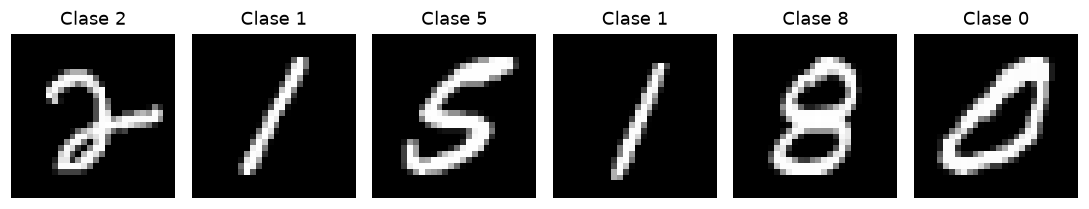

In [10]:
(imagenes_all, y_all), (imagenes_test, y_test) = tf.keras.datasets.mnist.load_data() #train: 60 000 ejemplos, almacenados en imagenes_all y y_all.
idx_train, idx_dev = train_test_split(np.arange(len(y_all)), test_size=6000,         #test: 10 000 ejemplos, almacenados en imagenes_test y y_test.
                                    stratify=y_all, random_state=SEED)
imagenes_train, y_train = imagenes_all[idx_train], y_all[idx_train]
imagenes_dev, y_dev = imagenes_all[idx_dev], y_all[idx_dev]
C = 10
assert set(idx_train).isdisjoint(idx_dev)
print("Ejemplos train/dev/test:", len(y_train), len(y_dev), len(y_test))
display(pd.DataFrame({"train": np.bincount(y_train, minlength=C),
                      "dev": np.bincount(y_dev, minlength=C)}, index=range(C)))
fig, axes = plt.subplots(1, 6, figsize=(10, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(imagenes_train[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Clase {y_train[i]}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [11]:
# Conteo de frecuencias sin dependencias externas
conteo_train = [0] * C
for etiqueta in y_train:
    conteo_train[etiqueta] += 1

conteo_dev = [0] * C
for etiqueta in y_dev:
    conteo_dev[etiqueta] += 1

def graficar_barras_ascii(conteos, titulo="Distribución de Clases", ancho_max=40):
    val_max = max(conteos)
    print(f"\n=== {titulo} ===")
    print(f"{'Clase':<6} | {'Frecuencia':<10} | {'Representación Gráfica'}")
    print("-" * (20 + ancho_max))
    
    for clase, conteo in enumerate(conteos):
        # Mapeo lineal de la frecuencia al ancho de caracteres
        longitud_barra = int((conteo / val_max) * ancho_max)
        barra = "█" * longitud_barra
        print(f"  {clase:<4} | {conteo:<10} | {barra}")

# Ejecución para el conjunto de entrenamiento
graficar_barras_ascii(conteo_train, titulo="Entrenamiento (train)", ancho_max=40)


=== Entrenamiento (train) ===
Clase  | Frecuencia | Representación Gráfica
------------------------------------------------------------
  0    | 5331       | ███████████████████████████████████
  1    | 6068       | ████████████████████████████████████████
  2    | 5362       | ███████████████████████████████████
  3    | 5518       | ████████████████████████████████████
  4    | 5258       | ██████████████████████████████████
  5    | 4879       | ████████████████████████████████
  6    | 5326       | ███████████████████████████████████
  7    | 5638       | █████████████████████████████████████
  8    | 5266       | ██████████████████████████████████
  9    | 5354       | ███████████████████████████████████


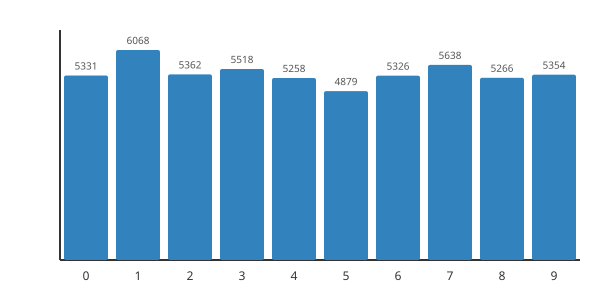

In [24]:
from IPython.display import SVG, display

def generar_svg_barras(conteos, ancho=600, alto=300, color="#3182bd"):
    num_clases = len(conteos)
    max_val = max(conteos)
    
    # Definición de márgenes en píxeles
    margin_left, margin_bottom, margin_top, margin_right = 60, 40, 30, 20
    ancho_util = ancho - margin_left - margin_right
    alto_util = alto - margin_bottom - margin_top
    
    ancho_bloque = ancho_util / num_clases
    padding = 8
    ancho_barra = ancho_bloque - padding
    
    y_eje = alto - margin_bottom
    
    # Encabezado SVG
    lines = [
        f'<svg width="{ancho}" height="{alto}" xmlns="http://www.w3.org/2000/svg" style="background:#fafafa; font-family:sans-serif;">',
        # Ejes X e Y
        f'  <line x1="{margin_left}" y1="{y_eje}" x2="{ancho - margin_right}" y2="{y_eje}" stroke="#333" stroke-width="2"/>',
        f'  <line x1="{margin_left}" y1="{margin_top}" x2="{margin_left}" y2="{y_eje}" stroke="#333" stroke-width="2"/>'
    ]
    
    # Construcción de rectángulos y textos explicativos
    for i, val in enumerate(conteos):
        h = (val / max_val) * (alto_util - 20)
        x = margin_left + i * ancho_bloque + (padding / 2)
        y = y_eje - h
        
        # Elemento rectángulo (barra)
        lines.append(f'  <rect x="{x:.1f}" y="{y:.1f}" width="{ancho_barra:.1f}" height="{h:.1f}" fill="{color}" rx="2"/>')
        # Etiqueta de la clase (Eje X)
        lines.append(f'  <text x="{x + ancho_barra/2:.1f}" y="{y_eje + 20}" font-size="12" text-anchor="middle" fill="#333">{i}</text>')
        # Valor numérico superior
        lines.append(f'  <text x="{x + ancho_barra/2:.1f}" y="{y - 6:.1f}" font-size="10" text-anchor="middle" fill="#555">{val}</text>')
        
    lines.append('</svg>')
    return "\n".join(lines)

# Visualización en Jupyter Notebook
codigo_svg = generar_svg_barras(conteo_train)
display(SVG(codigo_svg))

### 2.1 Nomenclatura y preprocesamiento
En todos nuestros arreglos principales **cada columna contiene un ejemplo**:

| Símbolo | Significado | Forma |
|---|---|---|
| $m$ | Número de ejemplos del conjunto | Escalar |
| $t$ | Tamaño de mini-batch | Escalar |
| $X=A^{[0]}$ | Imágenes aplanadas | $(784,m)$ |
| $Y$ | Etiquetas one-hot | $(10,m)$ |
| $W^{[l]}$ | Pesos de la capa $l$ | $(n^{[l]},n^{[l-1]})$ |
| $b^{[l]}$ | Sesgos | $(n^{[l]},1)$ |
| $Z^{[L]}$ | Logits de salida | $(10,m)$ |
| $A^{[L]}$ | Probabilidades softmax | $(10,m)$ |
| $\hat Y$ | Clases predichas | $(m,)$ en el código |

----
Diferencias entre `y_train` y `Y_train`:

`y_train` conserva etiquetas enteras; `Y_train` es su representación one-hot. One-hot no es obligatorio para entrenar una red neuronal multiclase.

Keras permite utilizar directamente etiquetas enteras mediante SparseCategoricalCrossentropy. En esta práctica utilizamos one-hot con CategoricalCrossentropy para relacionar la implementación con las ecuaciones matemáticas de softmax y entropía cruzada.

Keras es una API de TensorFlow (tf.keras), permite construir y entrenar redes neuronales.
-----



### 2.2 Normalización de entradas

Dividimos píxeles entre 255 para obtener $[0,1]$. Es un escalamiento con una constante conocida, no una estandarización con media/varianza. Dev, test y una imagen propia reciben exactamente la misma transformación.

---
Utilizamos el escalamiento a \([0,1]\) porque las imágenes MNIST tienen intensidades en el rango conocido de 0 a 255. La estandarización Z-score también es válida, pero no es indispensable para esta práctica. Ambas transformaciones ayudan a controlar la escala de las entradas, aunque ninguna garantiza por sí sola una mejor convergencia.

In [12]:
def preprocess_images(images):
    """Imágenes (m, 28, 28) -> matriz float32 (784, m), escalada a [0,1]."""
    images = np.asarray(images)
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        raise ValueError("Se esperan imágenes con forma (m, 28, 28).")
    return images.reshape(images.shape[0], -1).T.astype(np.float32) / 255.0

X_train = preprocess_images(imagenes_train)
X_dev = preprocess_images(imagenes_dev)
Y_train = one_hot_matrix(y_train, C=10).numpy()
Y_dev = one_hot_matrix(y_dev, C=10).numpy()

print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)
print("X_dev:  ", X_dev.shape, "| Y_dev:  ", Y_dev.shape)
print("Rango de píxeles:", X_train.min(), X_train.max())
assert X_train.shape == (784, 54000) and Y_train.shape == (10, 54000)
n_x, m_train = X_train.shape
assert np.isfinite(X_train).all()


X_train: (784, 54000) | Y_train: (10, 54000)
X_dev:   (784, 6000) | Y_dev:   (10, 6000)
Rango de píxeles: 0.0 1.0


## 3. Softmax y función de costo multiclase

En la capa de salida, la red calcula $Z^{[L]}$, cuyos valores se llaman **logits**.

La función **softmax** recibe $Z^{[L]}$ y lo transforma en probabilidades $A^{[L]}$ para las 10 clases:

$$
A_k^{[L]}=\frac{e^{Z_k^{[L]}}}{\sum_{j=0}^{9}e^{Z_j^{[L]}}}
$$

Cada neurona de salida representa una clase y las 10 probabilidades suman 1.

La **función de costo** utiliza las probabilidades predichas $A^{[L]}$ y las etiquetas verdaderas $Y$:

$$
J=-\frac{1}{t_b}\sum_{i=1}^{t_b}\sum_{k=0}^{9}
Y_{k,i}\log A_{k,i}^{[L]}
$$

Donde $t_b$ es el número de ejemplos del mini-batch.

**En TensorFlow:** `softmax_cross_entropy_with_logits` recibe directamente los logits $Z^{[L]}$ y calcula internamente softmax y la entropía cruzada de forma numéricamente estable. Por ello, **no debemos aplicar softmax antes de llamar a esta función**.

### Ejemplo: Softmax y estabilidad numérica

Esta celda demuestra que **softmax produce las mismas probabilidades cuando sumamos una constante a todos los logits de un ejemplo**.

Se utilizan dos ejemplos con tres clases:

- **Ejemplo 1:** $Z=[2,1,-1]$
- **Ejemplo 2:** $Z=[1002,1001,999]$

El segundo ejemplo tiene los mismos logits que el primero, pero aumentados en 1000.

---
1. `compute_cost()` calcula la entropía cruzada promedio directamente a partir de los logits $Z^{[L]}$ y las etiquetas $Y$.
2. `tf.nn.softmax()` obtiene las probabilidades $A^{[L]}$.
3. `assert_allclose()` verifica que ambos ejemplos producen las mismas probabilidades y que estas suman 1

In [13]:
def compute_cost(ZL, Y):
    """Calcula la entropía cruzada promedio a partir de logits y etiquetas one-hot (C, m)."""
    return tf.reduce_mean(tf.nn.softmax_cross_entropy_with_logits(
        logits=tf.transpose(ZL),  # Transpone de (C, m) a (m, C).
        labels=tf.transpose(tf.convert_to_tensor(Y, tf.float32))))

# Dos ejemplos: el segundo tiene los mismos logits +1000.
Z_ejemplo = tf.constant([[2., 1002.], [1., 1001.], [-1., 999.]])

# Etiquetas verdaderas: ambos ejemplos pertenecen a la clase 0.
Y_ejemplo = one_hot_matrix([0, 0], C=3)

# Calcula las probabilidades para cada clase (filas).
A_ejemplo = tf.nn.softmax(Z_ejemplo, axis=0)

# Muestra probabilidades y costo promedio.
print("Probabilidades:\n", A_ejemplo.numpy())
print("CE:", float(compute_cost(Z_ejemplo, Y_ejemplo)))

# Verifica que sumar 1000 a los logits no cambia las probabilidades.
np.testing.assert_allclose(A_ejemplo[:, 0], A_ejemplo[:, 1], atol=1e-6)

# Verifica que las probabilidades de cada ejemplo suman 1.
np.testing.assert_allclose(tf.reduce_sum(A_ejemplo, axis=0), 1., atol=1e-6)

Probabilidades:
 [[0.7053845  0.7053845 ]
 [0.25949648 0.25949648]
 [0.03511902 0.03511902]]
CE: 0.349012166261673


**RESPUESTA DEL ESTUDIANTE 2.** ¿Por qué sumar 1000 a todos los logits de un ejemplo no cambia softmax? ¿Por qué sería incorrecto pasar probabilidades a una función que espera logits? ¿Qué dimensiones tendrá un mini-batch de 128 ejemplos?

1. ¿Por qué sumar 1000 a todos los logits no cambia softmax?
Porque las diferencias relativas siguen siendo las mismas entre estos, entonces sus proporciones no cambian enormemente proporcional a los logits que les aumentamos, evitando errores de desbordamiento (Overflow) al calcular exponenciales de números muy grandes.
2. ¿Por qué sería incorrecto pasar probabilidades a una función que espera logits?
La función de pérdida aplicará una segunda transformación Softmax sobre valores que ya están acotados entre 0 y 1. Esto aplana la distribución de probabilidades, destruyendo la magnitud real de las diferencias y reduciendo drásticamente la magnitud de los gradientes.
3. ¿Qué dimensiones tendrá un mini-batch de 128 ejemplos?
Para MNIST, con 784 características y 10 clases:
- $X: (784,128)$
- $Y: (10,128)$ en one-hot.
- $Z^{[L]}, A^{[L]}: (10,128)$

## 4. Una red configurable que implementa las ecuaciones
Para cada capa oculta:
$$Z^{[l]}=W^{[l]}A^{[l-1]}+b^{[l]},\qquad A^{[l]}=g(Z^{[l]}).$$
La salida es lineal: $Z^{[L]}=W^{[L]}A^{[L-1]}+b^{[L]}$. La pérdida incorpora softmax.

Usamos `tf.keras` para crear variables de las capas y `GradientTape` para entrenarlas explícitamente. **Keras forma parte de este flujo de TensorFlow; no necesitamos escribir las derivadas a mano.**

- `Input`: dimensión de cada ejemplo.
- `Dense`: capa que calcula producto matricial más sesgo.
- `Activation`: aplica ReLU o tanh.
- `Sequential`: ejecuta las capas en orden.

Keras recibe ejemplos en **filas** y almacena `kernel` con forma $(n_{in},n_{out})$. Nuestra función `forward_propagation` hace las dos transposiciones necesarias para que **X y logits sigan usando columnas**. Para recuperar la notación del curso: `W = kernel.T`, `b = bias.reshape(-1,1)`.

`None` en `summary()` representa una cantidad variable de ejemplos, no una neurona adicional.

`Config` agrupa los hiperparámetros; `BASE = Config()` crea la referencia. Conserva esta referencia al comparar: introduce tus cambios mediante `replace(BASE, ...)` en la sección 8. La verificación manual de la sección 4.2 corresponde a la red base sin BN ni dropout.

In [14]:
#Agrupa los hiperparámetros utilizados para construir y entrenar la red.

@dataclass(frozen=True) #genera automáticamente el constructor de la clase; #frozen=True impide modificar sus valores después de crearla.
class Config:
    # Arquitectura de la red
    capas_ocultas: tuple = (32, 16)  # Dos capas ocultas: 32 y 16 neuronas.
    activacion: str = "relu"         # Función de activación de las capas ocultas.
    inicializacion: str = "he"       # Inicialización de pesos (recomendada para ReLU).

    # Optimización y entrenamiento
    optimizador: str = "adam"        # Algoritmo para actualizar los parámetros.
    alpha: float = 1e-3             # Tasa de aprendizaje (learning rate = 0.001).
    t: int = 128                    # Tamaño del mini-batch: 128 ejemplos.
    epocas: int = 10                # Número de recorridos completos por train.

    # Regularización: valores en cero significan que están desactivadas.
    lambda_l1: float = 0.0          # Intensidad de regularización L1.
    lambda_l2: float = 0.0          # Intensidad de regularización L2.
    dropout: float = 0.0            # Proporción de neuronas desactivadas en entrenamiento.
    batch_norm: bool = False        # Activa o desactiva Batch Normalization.

    # Ajustes adicionales
    decay: float = 0.0              # Decaimiento de la tasa de aprendizaje.
    seed: int = SEED                # Semilla para reproducibilidad.

# Configuración de referencia para todos los experimentos.
BASE = Config()

### 4.1 Inicialización y regularización
Usamos **He con ReLU**, sesgos cero y **Xavier en la salida lineal**. La opción `xavier` implementa GlorotNormal (varianza aproximada $2/(n_{in}+n_{out})$); no debe confundirse con la variante simplificada $1/n_{in}$. He usa aproximadamente $2/n_{in}$. Los inicializadores reciben la forma de kernel esperada por Keras.

n_in   # Número de neuronas de entrada a una capa (capa anterior).
n_out  # Número de neuronas de salida de esa capa (capa actual).

----

Los pesos distintos rompen la simetría entre neuronas. Los métodos `zeros` y `constant` se incluyen para diagnosticar sus problemas, no como opciones recomendadas. He/Xavier facilitan la optimización, pero no garantizan convergencia.

----

Para regularización definimos explícitamente:
$$J=J_{datos}+\frac{\lambda_2}{2m_{train}}\sum_l\|W^{[l]}\|_F^2+
\frac{\lambda_1}{m_{train}}\sum_l\|W^{[l]}\|_1.$$

Keras `L2(c)` calcula $c\sum W^2$, por eso usamos $c=\lambda_2/(2m_{train})$. Penalizamos kernels de todas las capas densas, incluidos los de salida; no sesgos ni parámetros de BN. No dividimos esta penalización otra vez por el tamaño del lote. Con Adam, agregar L2 a la pérdida no equivale en general a AdamW.

`Dropout(rate=q)` elimina una fracción $q$ y conserva `keep_prob=1-q`. Solo actúa entrenando. BN se coloca como `Dense → BN → activación` y se omite el sesgo de esa Dense porque BN ya tiene un desplazamiento aprendible. Sus detalles se estudian en la parte C.

In [15]:
# ============================================================
# 1. SELECCIÓN DEL MÉTODO DE INICIALIZACIÓN DE PESOS
# ============================================================

def inicializador(nombre, seed):
    """Devuelve el inicializador de pesos seleccionado."""

    opciones = {
        "he": lambda: tf.keras.initializers.HeNormal(seed=seed),          # He: recomendado para ReLU.
        "xavier": lambda: tf.keras.initializers.GlorotNormal(seed=seed),  # Xavier/Glorot: recomendado para tanh.
        "small": lambda: tf.keras.initializers.RandomNormal(
            stddev=0.01, seed=seed),                                     # Pesos aleatorios pequeños.
        "large": lambda: tf.keras.initializers.RandomNormal(
            stddev=2., seed=seed),                                       # Pesos aleatorios grandes.
        "zeros": lambda: tf.keras.initializers.Zeros(),                  # Todos los pesos en cero.
        "constant": lambda: tf.keras.initializers.Constant(0.05)         # Todos los pesos iguales a 0.05.
    }

    if nombre not in opciones:
        raise ValueError("Inicialización no reconocida.")

    return opciones[nombre]()


# ============================================================
# 2. CONSTRUCCIÓN DE LA RED NEURONAL
# ============================================================

def construir_modelo(cfg):
    """
    Construye una red neuronal multicapa (MLP) utilizando Keras.

    cfg: configuración con arquitectura, inicialización,
         activación y métodos de regularización.
    """

    # Verificar que la función de activación elegida sea relu o tanh
    if cfg.activacion not in ("relu", "tanh"):
        raise ValueError("Warning: Esta práctica admite relu o tanh en las capas ocultas.")

    if not cfg.capas_ocultas or any(
        not isinstance(a, int) or a < 1 for a in cfg.capas_ocultas
    ):
        raise ValueError("Usa una tupla de anchos enteros positivos.")

    if cfg.epocas < 1 or cfg.t < 1 or cfg.alpha <= 0:
        raise ValueError("epocas, t y alpha deben ser positivos.")

    if min(cfg.lambda_l1, cfg.lambda_l2, cfg.decay) < 0 or not 0 <= cfg.dropout < 1:
        raise ValueError("Revisa regularización, decay y dropout.")

    # Regularización L1 y L2 de los pesos: Elastic Net (L1 + L2): conduce a pesos a cero mientras reduce la magnitud de los restantes.
    # m_train: número total de ejemplos de entrenamiento.
    reg = tf.keras.regularizers.L1L2(
        l1=cfg.lambda_l1 / m_train,
        l2=cfg.lambda_l2 / (2 * m_train)
    )

    # Capa de entrada: n_x características por ejemplo.
    # Para MNIST, n_x = 784 (imagen de 28 x 28 aplanada).
    capas = [tf.keras.Input(shape=(n_x,))]

    # Construir las capas ocultas según cfg.capas_ocultas.
    # Ejemplo: (32, 16) crea dos capas ocultas de 32 y 16 neuronas.
    for l, ancho in enumerate(cfg.capas_ocultas, start=1):

        # Capa Dense: calcula Z = WA + b.
        # ancho = número de neuronas de salida de esta capa (n_out).
        # n_in queda determinado por la salida de la capa anterior.
        capas.append(tf.keras.layers.Dense(
            ancho,
            use_bias=not cfg.batch_norm,  # Sin sesgo si usamos Batch Normalization.
            kernel_initializer=inicializador(
                cfg.inicializacion, cfg.seed + l
            ),
            bias_initializer="zeros",
            kernel_regularizer=reg,
            name=f"lineal_{l}"
        ))

        # Batch Normalization: normaliza Z antes de la activación.
        if cfg.batch_norm:
            capas.append(tf.keras.layers.BatchNormalization(
                momentum=0.9,
                name=f"bn_{l}"
            ))

        # Función de activación: A = g(Z).
        capas.append(tf.keras.layers.Activation(
            cfg.activacion,
            name=f"activacion_{l}"
        ))

        # Dropout: desactiva aleatoriamente una proporción
        # de activaciones durante el entrenamiento.
        if cfg.dropout:
            capas.append(tf.keras.layers.Dropout(
                cfg.dropout,
                seed=cfg.seed + 100 + l
            ))

    # Capa de salida: C = 10 neuronas (una por clase de MNIST).
    # activation=None: devuelve logits Z^[L], sin aplicar softmax.
    capas.append(tf.keras.layers.Dense(
        C,
        activation=None,
        kernel_regularizer=reg,
        kernel_initializer=tf.keras.initializers.GlorotNormal(
            seed=cfg.seed + 50
        ),
        name="logits"
    ))

    # Sequential conecta las capas en el orden en que fueron agregadas.
    return tf.keras.Sequential(capas)


# ============================================================
# 3. PROPAGACIÓN HACIA ADELANTE (FORWARD PROPAGATION)
# ============================================================

def forward_propagation(X, modelo, training=False):
    """
    Calcula los logits Z^[L] de la red.

    Entrada:  X con dimensiones (n_x, m).
    Salida:   Z^[L] con dimensiones (C, m).

    training=True activa el comportamiento de entrenamiento
    de Dropout y Batch Normalization.
    """

    X = tf.convert_to_tensor(X, dtype=tf.float32)

    # Keras utiliza (m, n_x), mientras que en clase usamos (n_x, m).
    # Por ello, transponemos antes y después de pasar por el modelo.
    return tf.transpose(
        modelo(tf.transpose(X), training=training)
    )


# ============================================================
# 4. CREAR Y EXAMINAR LA ARQUITECTURA
# ============================================================

# Crear una red con los hiperparámetros de referencia.
modelo_demo = construir_modelo(BASE)

# Mostrar las capas, las dimensiones de salida y el número de parámetros.
modelo_demo.summary()


# ============================================================
# 5. MOSTRAR LAS DIMENSIONES DE LOS PARÁMETROS W Y b
# ============================================================

filas = []

# Recorrer únicamente las capas Dense (ocultas y salida).
for l, capa in enumerate(
    [c for c in modelo_demo.layers
     if isinstance(c, tf.keras.layers.Dense)], 1
):

    filas.append({
        "capa": l,

        # Keras almacena W con dimensiones (n_in, n_out).
        # Se invierten para mostrar (n_out, n_in), como en clase.
        "W": tuple(reversed(capa.kernel.shape)),

        # El sesgo b tiene dimensiones (n_out, 1).
        # Si se usa BN, la capa Dense no incluye sesgo.
        "b": (capa.units, 1) if capa.use_bias
             else "BN sustituye el sesgo"
    })

# Mostrar una tabla con las dimensiones de cada capa.
display(pd.DataFrame(filas))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lineal_1 (Dense)                │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activacion_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lineal_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activacion_2 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,818 (100.85 KB)

 Trainable params: 25,818 (100.85 KB)

 Non-trainable params: 0 (0.00 B)

,capa,W,b
0,1,"(32, 784)","(32, 1)"
1,2,"(16, 32)","(16, 1)"
2,3,"(10, 16)","(10, 1)"


### 4.2 Verificar la equivalencia con las ecuaciones
Antes de entrenar, recuperamos los pesos de la red base y calculamos la propagación usando `W @ A + b`. Debe coincidir con `forward_propagation`.

Esta comprobación corresponde al **modelo base sin BN ni dropout**. Esas técnicas agregan operaciones; no bastaría con multiplicar solamente sus matrices de pesos.

In [16]:
X_demo, Y_demo = X_train[:, :5], Y_train[:, :5]
A = tf.constant(X_demo)
capas_densas = [c for c in modelo_demo.layers if isinstance(c, tf.keras.layers.Dense)]
for l, capa in enumerate(capas_densas, start=1):
    kernel, bias = capa.get_weights()
    W, b = kernel.T, bias.reshape(-1,1)
    Z = W @ A + b
    A = (tf.nn.relu(Z) if BASE.activacion == "relu" else tf.nn.tanh(Z)) if l < len(capas_densas) else Z
ZL_demo = forward_propagation(X_demo, modelo_demo)
np.testing.assert_allclose(A.numpy(), ZL_demo.numpy(), atol=1e-5)
assert ZL_demo.shape == (C, 5)
print("Dimensiones y propagación verificadas. CE inicial:", float(compute_cost(ZL_demo, Y_demo)))

Dimensiones y propagación verificadas. CE inicial: 2.5524814128875732


**RESPUESTA DEL ESTUDIANTE 3.** Calcula el número de parámetros de la primera capa y compáralo con `summary()`.



Cálculo: Número de parámetros = (entradas × neuronas) + sesgos.
Para la primera capa de MNIST (784 entradas y 32 neuronas):
$(784\times32)+32=\boxed{25\,120\text{ parámetros}}$

- 25,088 pesos
- 32 sesgos
Este resultado debe coincidir con summary() para la primera capa Dense, cuando Batch Normalization está desactivada.

## 5. Backpropagation, optimizadores y mini-batches
El entrenamiento hace cuatro operaciones: propagación → pérdida → gradientes → actualización. `GradientTape` calcula derivadas; el optimizador define la regla para usarlas.

| Opción | Información que utiliza |
|---|---|
| SGD | Gradiente del lote actual |
| Momentum | Gradiente y velocidad acumulada |
| RMSprop | Media móvil de gradientes al cuadrado |
| Adam | Primer y segundo momentos, con corrección de sesgo |

**Convención de momentum:** Keras SGD usa `u = beta*u - alpha*g; W = W + u`. En la convención del curso, `v = beta*v + (1-beta)*g; W = W - alpha*v`. Las tasas numéricas no son directamente equivalentes. Con tasa constante, la equivalencia requiere `alpha_Keras = (1-beta)*alpha_curso`.

El `epsilon` de los optimizadores evita problemas al dividir por valores pequeños; no es el coeficiente de regularización. Cada entrenamiento crea un optimizador nuevo para no reutilizar momentos de otro modelo.

### Momentum: relación con el suavizado exponencial (EWA)

Recordemos que el **promedio exponencialmente ponderado (EWA)** suaviza una secuencia de valores:

$$
v_t=\beta v_{t-1}+(1-\beta)x_t
$$

Donde $\beta$ controla cuánto peso damos al historial y $x_t$ es el nuevo valor.

**Momentum aplica esta misma idea a los gradientes**, sustituyendo $x_t$ por $g_t=dW_t$.

**1. Momentum en el curso (Andrew Ng):**

$$
v_t=\beta v_{t-1}+(1-\beta)g_t
$$

$$
W_t=W_{t-1}-\alpha_{\text{curso}}v_t
$$

Primero suavizamos los gradientes y después actualizamos los pesos.

**2. Momentum en Keras (SGD):**

$$
u_t=\beta u_{t-1}-\alpha_{\text{Keras}}g_t
$$

$$
W_t=W_{t-1}+u_t
$$

Keras acumula directamente los desplazamientos de los pesos. El signo negativo ya está incluido en $u_t$.

**¿Son equivalentes?**

Sí, si parten de estados iniciales en cero y utilizan tasas constantes, ajustando:

$$
\boxed{\alpha_{\text{Keras}}=(1-\beta)\alpha_{\text{curso}}}
$$

Por ejemplo, con $\beta=0.9$ y $\alpha_{\text{curso}}=0.01$, corresponde $\alpha_{\text{Keras}}=0.001$.

**Notas:**
- `epsilon` evita problemas numéricos al dividir entre valores muy pequeños en optimizadores como RMSprop y Adam; no es un coeficiente de regularización.
- Cada entrenamiento crea un optimizador nuevo para evitar reutilizar los promedios acumulados de gradientes de otro modelo.

In [17]:
# Selecciona el optimizador definido en Config.
def crear_optimizador(cfg):
    if cfg.optimizador == "sgd":
        return tf.keras.optimizers.SGD(learning_rate=cfg.alpha)  # Descenso de gradiente.
    if cfg.optimizador == "momentum":
        return tf.keras.optimizers.SGD(learning_rate=cfg.alpha, momentum=0.9)  # Acumula desplazamientos.
    if cfg.optimizador == "rmsprop":
        return tf.keras.optimizers.RMSprop(learning_rate=cfg.alpha, rho=0.9, epsilon=1e-7)  # Suaviza gradientes cuadrados.
    if cfg.optimizador == "adam":
        return tf.keras.optimizers.Adam(learning_rate=cfg.alpha, beta_1=0.9, beta_2=0.999, epsilon=1e-7)  # Combina Momentum y RMSprop.
    raise ValueError("Optimizador no reconocido.")

# Demostración: una sola actualización de los pesos con cinco ejemplos.
opt_demo = crear_optimizador(BASE)

# Calcula el costo J y registra las operaciones para obtener gradientes.
with tf.GradientTape() as tape:
    ZL = forward_propagation(X_demo, modelo_demo, training=True)  # Propagación hacia adelante.
    J_demo = compute_cost(ZL, Y_demo) + tf.add_n(modelo_demo.losses)  # Entropía cruzada + regularización.

# Calcula los gradientes dJ/dW y dJ/db (backpropagation).
gradientes = tape.gradient(J_demo, modelo_demo.trainable_variables)

# Verifica que se calcularon todos los gradientes.
assert all(g is not None for g in gradientes)

# Actualiza los parámetros usando el optimizador seleccionado.
opt_demo.apply_gradients(zip(gradientes, modelo_demo.trainable_variables))

# Compara el costo antes y después de actualizar los pesos.
print("CE antes del paso:", float(J_demo))
print("CE después del paso:", float(compute_cost(forward_propagation(X_demo, modelo_demo), Y_demo)))

CE antes del paso: 2.5524814128875732
CE después del paso: 2.391448497772217


### 5.1 Conservar todos los ejemplos
Una época recorre train completo. El último mini-batch puede tener menos de $t$ ejemplos. Se barajan índices, y el mismo orden se aplica a $X$ y $Y$.

Hay $\lceil m_{train}/t\rceil$ actualizaciones por época. Cambiar $t$ manteniendo épocas también cambia el número de actualizaciones, por lo que registraremos ambos.

En cada época se mezclan los ejemplos y se dividen en mini-batches de tamaño \(t\). Si el número total de ejemplos \(m\) no es divisible entre \(t\), el último mini-batch contiene los ejemplos restantes. Ningún ejemplo se pierde ni se repite dentro de una época.

In [18]:
def mini_batches(X, Y, t, rng):
    """
    Divide los datos en mini-batches aleatorios.
    X: (n_x, m), Y: (C, m), t: tamaño del mini-batch.
    rng: generador de números aleatorios.
    """

    # Verifica que t sea positivo y que X e Y tengan el mismo número de ejemplos.
    if t < 1 or X.shape[1] != Y.shape[1]:
        raise ValueError("Revisa el tamaño del lote y la cantidad de ejemplos.")

    # Mezcla aleatoriamente los índices de los m ejemplos.
    orden = rng.permutation(X.shape[1])

    # Recorre los ejemplos en grupos de tamaño t.
    for inicio in range(0, X.shape[1], t):
        ids = orden[inicio:inicio+t]  # Índices del mini-batch actual.

        # Devuelve X e Y correspondientes al mismo grupo de ejemplos.
        yield X[:, ids], Y[:, ids]


# ============================================================
# DEMOSTRACIÓN: 10 ejemplos divididos en mini-batches de 4.
# ============================================================

# Crea 10 ejemplos identificados con números del 0 al 9.
ids_demo = np.arange(10, dtype=np.float32).reshape(1, -1)

# Genera los mini-batches: 4, 4 y 2 ejemplos.
lotes = list(mini_batches(ids_demo, ids_demo, 4, np.random.default_rng(SEED)))

# Verifica que los tamaños sean 4, 4 y 2.
assert [x.shape[1] for x, y in lotes] == [4, 4, 2]

# Verifica que los 10 ejemplos aparezcan exactamente una vez.
np.testing.assert_array_equal(
    np.sort(np.concatenate([x.ravel() for x, y in lotes])),
    np.arange(10)
)

print("Último lote y cobertura de ejemplos verificados.")

Último lote y cobertura de ejemplos verificados.


## 6. Entrenamiento completo y evaluación con dev
En cada lote optimizamos CE + regularización. Al terminar la época evaluamos **train y dev en modo inferencia**, para comparar su CE sin penalización y sin dropout. BN usa entonces sus estadísticas móviles.

`@tf.function` compila el paso para repetirlo de forma eficiente. `None` permite un número variable de columnas. La primera llamada incluye tiempo de compilación.

Conservamos el checkpoint de **menor CE en dev** y restauramos todos los pesos, incluidas las estadísticas móviles de BN. Se ejecuta un número fijo de épocas; no hay parada anticipada. El checkpoint sirve para inferencia, no para reanudar exactamente el optimizador.

Decay por época: $\alpha_e=\alpha_0/(1+d(e-1))$, con épocas numeradas desde 1. Si $d=0$, la tasa es constante.

El objetivo promedio durante la época pondera por el tamaño real de cada lote. La norma de gradientes combina todos los parámetros entrenables; es un diagnóstico, no un criterio que deba minimizarse por sí mismo.

### Ciclo de entrenamiento de una red neuronal

Esta implementación permite reconocer el ciclo de entrenamiento estudiado teóricamente:

$$
\boxed{
\text{Mini-batch}
\rightarrow \text{Forward}
\rightarrow J
\rightarrow \text{Backpropagation}
\rightarrow \text{Actualizar parámetros}
}
$$

Este proceso se repite para todos los mini-batches de cada época.

Al finalizar cada época, se evalúa el modelo en **train y dev**, y se conservan los pesos de la época con menor pérdida en dev.

In [19]:
# ============================================================
# 1. EVALUACIÓN DEL MODELO
# ============================================================

def evaluar(modelo, X, Y, t=1024):
    """Calcula entropía cruzada (CE) y exactitud (accuracy)."""

    total_ce, correctos = 0., 0
    m = X.shape[1]  # Número total de ejemplos.

    # Evalúa por lotes para reducir el uso de memoria.
    for inicio in range(0, m, t):
        xb, yb = X[:, inicio:inicio+t], Y[:, inicio:inicio+t]

        # Forward propagation sin Dropout y con BN en modo inferencia.
        ZL = forward_propagation(xb, modelo, training=False)

        # Acumula la CE ponderada por el tamaño del lote.
        total_ce += float(compute_cost(ZL, yb)) * xb.shape[1]

        # Compara la clase predicha con la clase verdadera.
        correctos += int(np.sum(
            np.argmax(ZL.numpy(), axis=0) == np.argmax(yb, axis=0)
        ))

    # Devuelve las métricas promedio.
    return {"CE": total_ce/m, "accuracy": correctos/m}


# ============================================================
# 2. ENTRENAMIENTO DEL MODELO
# ============================================================

def entrenar(cfg, verbose=True):
    """Entrena la red y conserva los pesos de la mejor época en dev."""

    # Inicializa semillas, modelo, optimizador y generador aleatorio.
    tf.keras.utils.set_random_seed(cfg.seed)
    modelo = construir_modelo(cfg)
    opt = crear_optimizador(cfg)
    rng = np.random.default_rng(cfg.seed)

    # Compila el paso de entrenamiento para acelerar su ejecución.
    @tf.function(input_signature=[
        tf.TensorSpec((n_x, None), tf.float32),
        tf.TensorSpec((C, None), tf.float32)
    ])
    def paso(xb, yb):

        # Forward propagation y cálculo del costo.
        with tf.GradientTape() as tape:
            ZL = forward_propagation(xb, modelo, training=True)
            J = compute_cost(ZL, yb) + tf.add_n(modelo.losses)

        # Backpropagation: calcula los gradientes.
        grads = tape.gradient(J, modelo.trainable_variables)

        # Calcula la norma global de los gradientes.
        norma = tf.linalg.global_norm(grads)

        # Detecta costos o gradientes NaN/infinito.
        tf.debugging.assert_all_finite(J, "Costo no finito: revisa escala y alpha.")
        tf.debugging.assert_all_finite(norma, "Gradientes no finitos: revisa escala y alpha.")

        # Actualiza los pesos y sesgos.
        opt.apply_gradients(zip(grads, modelo.trainable_variables))

        return J, norma

    # Variables para registrar resultados y seleccionar el mejor modelo.
    filas, mejor_CE, mejores_pesos, mejor_epoca = [], np.inf, None, None
    inicio_total = time.perf_counter()

    # Entrenamiento durante el número de épocas definido en Config.
    for e in range(1, cfg.epocas+1):

        # Decaimiento de la tasa de aprendizaje por época.
        alpha = cfg.alpha / (1 + cfg.decay * (e-1))
        opt.learning_rate.assign(alpha)

        suma_J, suma_norma = 0., 0.

        # Recorre todos los mini-batches de la época.
        for xb, yb in mini_batches(X_train, Y_train, cfg.t, rng):
            J, norma = paso(xb, yb)

            # Acumula costo y norma ponderados por tamaño del lote.
            suma_J += float(J) * xb.shape[1]
            suma_norma += float(norma) * xb.shape[1]

        # Evalúa el modelo en train y dev al terminar la época.
        tr = evaluar(modelo, X_train, Y_train)
        dv = evaluar(modelo, X_dev, Y_dev)

        # Guarda las métricas y el tiempo acumulado.
        filas.append({
            "epoca": e,
            "J_lotes": suma_J/m_train,
            "norma_grad": suma_norma/m_train,
            "CE_train": tr["CE"],
            "CE_dev": dv["CE"],
            "acc_train": tr["accuracy"],
            "acc_dev": dv["accuracy"],
            "alpha": alpha,
            "segundos": time.perf_counter()-inicio_total
        })

        # Conserva los pesos de la época con menor CE en dev.
        if dv["CE"] < mejor_CE:
            mejor_CE = dv["CE"]
            mejores_pesos = modelo.get_weights()
            mejor_epoca = e

        # Muestra el progreso del entrenamiento.
        if verbose:
            print(
                f"Época {e:2d} | CE train={tr['CE']:.4f} | "
                f"CE dev={dv['CE']:.4f} | acc dev={dv['accuracy']:.2%}"
            )

    # Recupera los pesos de la mejor época.
    modelo.set_weights(mejores_pesos)

    # Devuelve modelo, historial y métricas finales.
    return {
        "modelo": modelo,
        "cfg": cfg,
        "history": pd.DataFrame(filas),
        "mejor_epoca": mejor_epoca,
        "train": evaluar(modelo, X_train, Y_train),
        "dev": evaluar(modelo, X_dev, Y_dev)
    }

## 7. Ejecutar el modelo base
Se usan los **54 000 ejemplos** de train en cada época; no hay reducción silenciosa de datos. El tiempo depende del equipo. Durante la parte C, conserva la partición y el presupuesto de entrenamiento para comparaciones controladas.

Si train y dev son pobres, revisa capacidad y optimización. Si train es bueno y dev empeora, investiga sobreajuste. Una brecha pequeña no implica buen desempeño si ambos errores son altos.

Época  1 | CE train=0.2636 | CE dev=0.2829 | acc dev=91.97%
Época  2 | CE train=0.1943 | CE dev=0.2171 | acc dev=93.65%
Época  3 | CE train=0.1660 | CE dev=0.1916 | acc dev=94.50%
Época  4 | CE train=0.1441 | CE dev=0.1725 | acc dev=94.88%
Época  5 | CE train=0.1306 | CE dev=0.1664 | acc dev=94.92%
Época  6 | CE train=0.1169 | CE dev=0.1558 | acc dev=95.50%
Época  7 | CE train=0.1081 | CE dev=0.1469 | acc dev=95.72%
Época  8 | CE train=0.1031 | CE dev=0.1470 | acc dev=95.72%
Época  9 | CE train=0.0989 | CE dev=0.1500 | acc dev=95.58%
Época 10 | CE train=0.0961 | CE dev=0.1483 | acc dev=95.47%


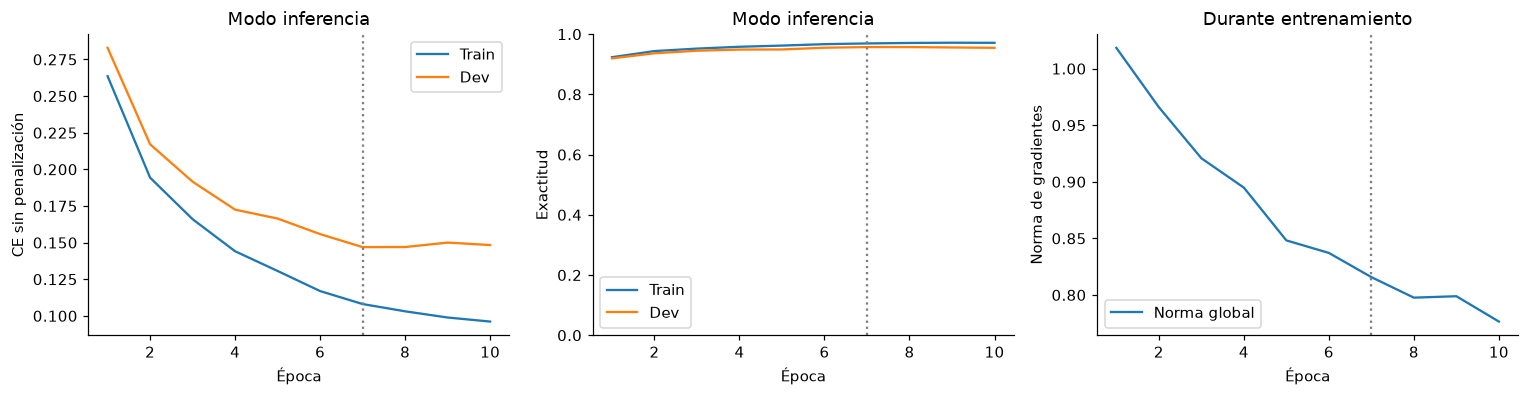

Checkpoint de menor CE dev: época 7


In [20]:
# Entrena el modelo con la configuración BASE y guarda los resultados.
resultados = {"base": entrenar(BASE)}

# Grafica la evolución del entrenamiento.
def graficar_historia(r):
    h = r["history"]  # Historial de métricas por época.

    # Crea tres gráficas: pérdida, exactitud y norma de gradientes.
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))

    # Gráfica 1: entropía cruzada en train y dev.
    for col, label in [("CE_train", "Train"), ("CE_dev", "Dev")]:
        axes[0].plot(h.epoca, h[col], label=label)

    # Gráfica 2: exactitud (accuracy) en train y dev.
    for col, label in [("acc_train", "Train"), ("acc_dev", "Dev")]:
        axes[1].plot(h.epoca, h[col], label=label)

    # Gráfica 3: norma global de los gradientes.
    axes[2].plot(h.epoca, h.norma_grad, label="Norma global")

    # Títulos y etiquetas de los ejes.
    axes[0].set(ylabel="CE sin penalización", title="Modo inferencia")
    axes[1].set(ylabel="Exactitud", title="Modo inferencia", ylim=(0, 1))
    axes[2].set(ylabel="Norma de gradientes", title="Durante entrenamiento")

    # Marca con una línea vertical la época con menor CE en dev.
    for ax in axes:
        ax.axvline(r["mejor_epoca"], color="gray", ls=":")
        ax.set_xlabel("Época")
        ax.legend()

    # Ajusta y muestra las gráficas.
    plt.tight_layout()
    plt.show()


# Grafica los resultados del modelo BASE.
graficar_historia(resultados["base"])

# Muestra la época cuyos pesos se conservaron.
print("Checkpoint de menor CE dev: época", resultados["base"]["mejor_epoca"])

Las gráficas permiten observar la evolución del aprendizaje, identificar posibles señales de sobreajuste y analizar el comportamiento de los gradientes. La línea vertical punteada indica la época con menor entropía cruzada en dev, cuyos pesos se conservaron como el mejor modelo.

**RESPUESTA DEL ESTUDIANTE 4.** ¿El costo disminuye? ¿Qué brecha observas entre train y dev? Usa cifras de las curvas. ¿Qué diferencia existe entre la última época y la época conservada?



1. **¿El costo disminuye?** Sí, normalmente la entropía cruzada disminuye conforme la red aprende. Se debe comprobar con los valores de las curvas.

2. **¿Qué brecha observas entre train y dev?** Se calcula como:

   $$\text{Brecha}=CE_{dev}-CE_{train}$$

   Por ejemplo, si train = 0.10 y dev = 0.15, la brecha es **0.05**. Una brecha creciente puede indicar sobreajuste.

3. **¿Qué diferencia existe entre la última época y la época conservada?** La última época corresponde al final del entrenamiento, mientras que la época conservada es aquella con **menor CE en dev**. No necesariamente coinciden.

## 8. Integrar los conceptos mediante experimentos
**Orden:** hipótesis → experimento → evidencia de dev → explicación. Todo este bloque va antes de test.

La función `replace(BASE, ...)` crea una configuración modificada y conserva las demás opciones. Cada llamada a `entrenar` reinicia pesos, optimizador y orden aleatorio. No continúa el modelo anterior.

### 8.1 Inicialización: mirar activaciones antes de entrenar
Compararemos varias inicializaciones ocultas manteniendo ReLU, sin BN ni dropout. Observa `std(Z)`, `std(A)` y fracción de ReLU activas. Pesos pequeños pueden comprimir la señal; muy grandes pueden amplificarla. Una constante puede producir valores no nulos y mantener neuronas redundantes.

En esta tabla se estudian activaciones; la norma de gradientes del bloque anterior complementa el diagnóstico. No deduzcas explosión o convergencia a partir de un único número.

En este diagnóstico fijamos explícitamente ReLU y desactivamos BN/dropout para que solo cambie la inicialización.

In [21]:
# Compara el efecto de seis métodos de inicialización en las capas ocultas.
filas_init = []

for metodo in ("zeros", "constant", "small", "large", "xavier", "he"):

    # Construye una red con ReLU, sin Batch Normalization ni Dropout.
    demo = construir_modelo(replace(
        BASE, inicializacion=metodo, activacion="relu",
        batch_norm=False, dropout=0.
    ))

    # Selecciona 128 ejemplos: Keras utiliza dimensiones (m, n_x).
    A = tf.constant(X_train[:, :128].T)

    l = 0  # Contador de capas Dense.

    # Recorre las capas para analizar sus activaciones.
    for capa in demo.layers:

        if isinstance(capa, tf.keras.layers.Dense):
            l += 1

            # Excluye la capa de salida (logits).
            if capa.name == "logits":
                break

            Z = capa(A)  # Calcula Z = WA + b.

        else:
            A = capa(Z)  # Aplica ReLU: A = max(0, Z).

            # Registra estadísticas de cada capa oculta.
            filas_init.append({
                "metodo": metodo,
                "capa": l,
                "std_Z": float(tf.math.reduce_std(Z)),  # Dispersión de Z.
                "std_A": float(tf.math.reduce_std(A)),  # Dispersión de A.
                "fraccion_activa": float(
                    tf.reduce_mean(tf.cast(A > 0, tf.float32))
                )  # Proporción de activaciones positivas (ReLU).
            })

# Organiza y muestra los resultados con cuatro decimales.
diagnostico = pd.DataFrame(filas_init)
display(diagnostico.round(4))

,metodo,capa,std_Z,std_A,fraccion_activa
0,zeros,1,0.0000,0.0000,0.0000
1,zeros,2,0.0000,0.0000,0.0000
2,constant,1,1.7913,1.7913,1.0000
3,constant,2,2.8661,2.8661,1.0000
4,small,1,0.0878,0.0529,0.4897
5,small,2,0.0037,0.0025,0.6050
6,large,1,17.5606,10.5723,0.4897
7,large,2,149.6343,100.7303,0.6050
8,xavier,1,0.4160,0.2776,0.5588
9,xavier,2,0.3919,0.2041,0.3921


Esto permite identificar cómo la inicialización afecta la propagación de las activaciones antes del entrenamiento. std_Z y std_A miden su dispersión, mientras que fraccion_activa indica la proporción de activaciones positivas después de ReLU.
Aquí estamos analizando las activaciones, no los gradientes, por lo que no demuestra directamente si existe explosión o desvanecimiento de gradientes.

### 8.2 Promedio móvil: suavizar sin cambiar el entrenamiento
Para una serie de costos $s_e$, $v_e=\beta v_{e-1}+(1-\beta)s_e$, $v_0=0$. La corrección inicial es $\hat v_e=v_e/(1-\beta^e)$.

Con $\beta=0.9$, el nuevo valor aporta 10%. La memoria aproximada es $1/(1-\beta)$, sin una ventana de corte rígido. Aquí solo suavizamos una gráfica; momentum promedia gradientes, RMSprop sus cuadrados y Adam combina ambos momentos. Selecciona el modelo con CE de dev sin suavizar.

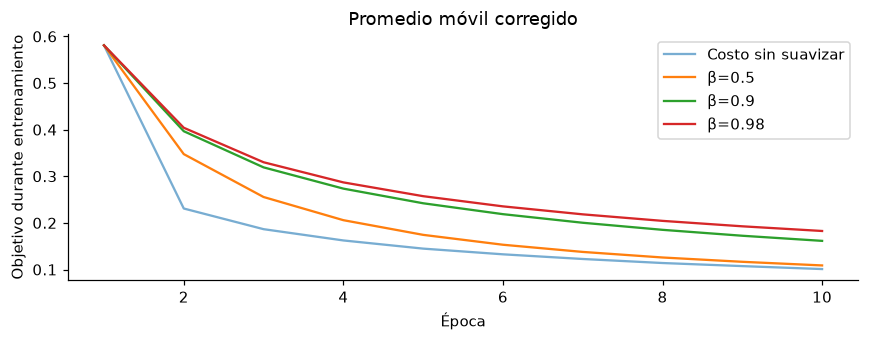

In [22]:
# Calcula el promedio móvil exponencial (EWA) con corrección de sesgo.
def promedio_movil(valores, beta=0.9):
    v, salida = 0., []  # Inicializa el promedio y la lista de resultados.

    for e, s in enumerate(valores, 1):
        v = beta*v + (1-beta)*s       # Suaviza el valor actual usando el historial.
        salida.append(v/(1-beta**e))  # Corrige el sesgo inicial hacia cero.

    return np.array(salida)


# Recupera el historial de entrenamiento del modelo BASE.
h = resultados["base"]["history"]

# Crea la gráfica del costo por época.
fig, ax = plt.subplots(figsize=(8, 3.2))

# Muestra el costo original sin suavizado.
ax.plot(h.epoca, h.J_lotes, label="Costo sin suavizar", alpha=0.6)

# Compara el suavizado con diferentes valores de beta.
for beta in (0.5, 0.9, 0.98):
    ax.plot(
        h.epoca,
        promedio_movil(h.J_lotes, beta),
        label=f"β={beta}"
    )

# Configura títulos, ejes y leyenda.
ax.set(
    xlabel="Época",
    ylabel="Objetivo durante entrenamiento",
    title="Promedio móvil corregido"
)

ax.legend()
plt.tight_layout()
plt.show()

Cuanto mayor es $beta$, mayor es el suavizado y más lentamente responde el promedio a los cambios. La corrección $1-\beta^e$ reduce el sesgo inicial producido por comenzar con $v=0$.
Este suavizado se aplica únicamente a la visualización del costo; no modifica el entrenamiento ni los pesos de la red.

### 8.3 Batch normalization y dropout: entrenamiento e inferencia
BN transforma cada característica del lote mediante
$$\tilde z=\gamma\frac{z-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}+\beta.$$
$\gamma$ y $\beta$ se aprenden por gradiente. Entrenando se usan estadísticas del lote; en inferencia se usan medias y varianzas móviles. El `momentum` de BN controla esas medias, no la velocidad del optimizador.

BN puede facilitar la optimización y añade ruido de lote, pero no garantiza mejores resultados ni menor tiempo. Dropout aplica máscaras en entrenamiento y se desactiva al inferir. Usar `training=False` en dev/test evita modificar las estadísticas de BN.

La demostración usa capas aisladas, así no altera modelos entrenados.

In [23]:
# ============================================================
# 1. DROPOUT: ENTRENAMIENTO VS. INFERENCIA
# ============================================================

# Dropout desactiva aleatoriamente el 50% de las entradas.
drop_demo = tf.keras.layers.Dropout(0.5, seed=SEED)

# Matriz de 3 ejemplos y 6 características, todas iguales a 1.
unos = tf.ones((3, 6))

# Entrenamiento: algunas entradas se anulan y las restantes se escalan.
print("Dropout entrenando:\n", drop_demo(unos, training=True).numpy())

# Inferencia: Dropout se desactiva; las entradas no cambian.
print("Dropout inferencia:\n", drop_demo(unos, training=False).numpy())


# ============================================================
# 2. BATCH NORMALIZATION: EFECTO DEL MINI-BATCH
# ============================================================

# Crea una capa BN; momentum=0.9 suaviza las estadísticas acumuladas.
bn_demo = tf.keras.layers.BatchNormalization(momentum=0.9)

# Primer mini-batch: dos ejemplos con dos características.
a = bn_demo(tf.constant([[1., 2.], [3., 4.]]), training=True)

# Segundo mini-batch: mismo primer ejemplo, pero cambia el segundo.
b = bn_demo(tf.constant([[1., 2.], [30., 40.]]), training=True)

# Compara la salida del mismo ejemplo en diferentes mini-batches.
print("Mismo ejemplo, distinto lote:", a[0].numpy(), b[0].numpy())

Dropout entrenando:
 [[0. 0. 2. 0. 0. 2.]
 [2. 0. 0. 0. 2. 0.]
 [0. 0. 2. 2. 2. 0.]]
Dropout inferencia:
 [[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]
Mismo ejemplo, distinto lote: [-0.9995004 -0.9995005] [-0.99999756 -0.99999857]


### 8.4 Activar comparaciones controladas
### Comparación de hiperparámetros y técnicas de entrenamiento

En esta sección compararemos diferentes configuraciones de la red neuronal, modificando **un hiperparámetro o técnica a la vez**, y utilizando el modelo `BASE` como referencia.

**Instrucciones:**

1. En `EXPERIMENTOS_A_EJECUTAR`, selecciona las variantes que deseas entrenar. Inicialmente, la lista está vacía.
2. Ejecuta al menos las siguientes variantes:
   - `amplia`: modifica el número de neuronas.
   - `L2`: incorpora regularización L2.
   - `dropout`: aplica Dropout.
   - `BN`: incorpora Batch Normalization.
   - `decay`: reduce progresivamente la tasa de aprendizaje.
   - **Un optimizador adicional:** compara Adam con SGD, Momentum o RMSprop.
3. Compara los resultados con `BASE` utilizando **CE y accuracy en dev**, las curvas de aprendizaje y el tiempo de entrenamiento.
4. Si aumentas el número de épocas, vuelve a entrenar `BASE` con el mismo número para realizar una comparación justa.

**Consideraciones importantes:**

- **Optimizadores:** primero compara con una tasa de aprendizaje común. Después, prueba distintas tasas para cada optimizador, utilizando el mismo número de candidatos. Una sola tasa no permite determinar cuál es mejor.
- **Mini-batches:** cambiar el tamaño del mini-batch modifica el número de actualizaciones por época.
- **Batch Normalization:** compara con y sin BN utilizando la misma tasa de aprendizaje. Recuerda que BN también introduce parámetros entrenables.
- **Tiempo:** los tiempos incluyen compilación y evaluación, por lo que son únicamente orientativos.

**Objetivo:** identificar cómo cada técnica afecta el entrenamiento, la convergencia y la capacidad de generalización de la red.

In [24]:
# ============================================================
# COMPARACIÓN CONTROLADA DE HIPERPARÁMETROS
# ============================================================

# Crea variantes de BASE modificando los hiperparámetros indicados.
# replace() conserva los demás valores de la configuración original.
variantes = {
    # Arquitectura de la red
    "amplia": replace(BASE, capas_ocultas=(128,64)),       # Más neuronas por capa.
    "tres_capas": replace(BASE, capas_ocultas=(64,32,16)), # Tres capas ocultas.

    # Inicialización de pesos
    "xavier": replace(BASE, inicializacion="xavier"),     # Inicialización Xavier/Glorot.

    # Regularización
    "L1": replace(BASE, lambda_l1=1.),                    # Penalización L1.
    "L2": replace(BASE, lambda_l2=10.),                   # Penalización L2.
    "dropout": replace(BASE, dropout=0.25),               # Desactiva 25% de activaciones.

    # Optimizadores
    "SGD": replace(BASE, optimizador="sgd"),              # Descenso de gradiente.
    "momentum": replace(BASE, optimizador="momentum"),    # SGD con Momentum.
    "RMSprop": replace(BASE, optimizador="rmsprop"),      # RMSprop.

    # Tamaño del mini-batch
    "batch_32": replace(BASE, t=32),                      # Mini-batches de 32 ejemplos.

    # Tasa de aprendizaje
    "decay": replace(BASE, decay=0.08),                   # Disminuye alpha por época.
    "alpha_alta": replace(BASE, alpha=1e-2),              # Tasa de aprendizaje 0.01.

    # Batch Normalization
    "BN": replace(BASE, batch_norm=True),                 # Activa Batch Normalization.
    "BN_alpha_alta": replace(BASE, alpha=1e-2,
                             batch_norm=True)            # BN con alpha = 0.01.
}

# Selecciona las variantes que deseas entrenar.
# Lista vacía = no se ejecutan experimentos adicionales.
EXPERIMENTOS_A_EJECUTAR = []  # Ejemplo: ["L2", "dropout", "BN"]

# Entrena únicamente las variantes seleccionadas.
for nombre in EXPERIMENTOS_A_EJECUTAR:

    # Verifica que la variante exista.
    if nombre not in variantes:
        raise ValueError(f"Variante desconocida: {nombre}")

    # Entrena y guarda los resultados de cada variante.
    resultados[nombre] = entrenar(variantes[nombre], verbose=False)

    # Muestra la CE y accuracy obtenidas en dev.
    print(nombre, resultados[nombre]["dev"])

Cada variante modifica uno o más hiperparámetros de BASE. Para comparar el efecto individual de una técnica, mantén constantes los demás valores. La variante BN_alpha_alta es una excepción deliberada, pues combina Batch Normalization con una tasa de aprendizaje mayor.

---
EXPERIMENTOS_A_EJECUTAR = [
    "amplia", "L2", "dropout", "BN", "decay", "RMSprop"
]

### 8.5 Tu experimento y búsqueda aleatoria
Elige primero una hipótesis que cambie un solo factor. Para explorar combinaciones de hiperparámetros puedes usar búsqueda aleatoria: la tasa se muestrea en escala logarítmica, por ejemplo $10^u$ con $u$ uniforme entre −4 y −2.

La búsqueda ayuda a seleccionar; cuando cambia varios factores a la vez no permite atribuir la mejora a uno solo. Tres candidatos ilustran el procedimiento, no garantizan encontrar el óptimo.

Si hay resultados muy cercanos, repite las dos configuraciones finalistas con varias semillas antes de test y compara media y desviación de CE de dev. Eso mide sensibilidad a la inicialización y al orden de lotes con la partición fija; no es validación cruzada.

In [27]:
EJECUTAR_MI_EXPERIMENTO=True
MI_CONFIG=replace(BASE,alpha=3e-3)  # Modifica y justifica antes de ejecutar.
if EJECUTAR_MI_EXPERIMENTO:
    resultados["mi_experimento"]=entrenar(MI_CONFIG)

EJECUTAR_BUSQUEDA=True
rng_busqueda=np.random.default_rng(SEED+1000)
configs_busqueda=[replace(BASE,alpha=float(10**rng_busqueda.uniform(-4,-2)),
    lambda_l2=float(10**rng_busqueda.uniform(-1,2)),dropout=float(rng_busqueda.choice([0.,0.15,0.3])))
    for _ in range(3)]
if EJECUTAR_BUSQUEDA:
    for k,cfg in enumerate(configs_busqueda,1):
        resultados[f"busqueda_{k}"]=entrenar(cfg,verbose=False)
        print(f"Búsqueda {k}:",asdict(cfg))

Época  1 | CE train=0.1923 | CE dev=0.2236 | acc dev=93.55%
Época  2 | CE train=0.1607 | CE dev=0.1941 | acc dev=94.65%
Época  3 | CE train=0.1157 | CE dev=0.1569 | acc dev=95.52%
Época  4 | CE train=0.0914 | CE dev=0.1402 | acc dev=95.72%
Época  5 | CE train=0.0921 | CE dev=0.1506 | acc dev=95.62%
Época  6 | CE train=0.0819 | CE dev=0.1427 | acc dev=95.90%
Época  7 | CE train=0.0623 | CE dev=0.1257 | acc dev=96.33%
Época  8 | CE train=0.0795 | CE dev=0.1509 | acc dev=95.83%
Época  9 | CE train=0.0624 | CE dev=0.1398 | acc dev=96.23%
Época 10 | CE train=0.0583 | CE dev=0.1366 | acc dev=96.27%
Búsqueda 1: {'capas_ocultas': (32, 16), 'activacion': 'relu', 'inicializacion': 'he', 'optimizador': 'adam', 'alpha': 0.0005185814332105699, 't': 128, 'epocas': 10, 'lambda_l1': 0.0, 'lambda_l2': 1.3080549135533435, 'dropout': 0.0, 'batch_norm': False, 'decay': 0.0, 'seed': 42}
Búsqueda 2: {'capas_ocultas': (32, 16), 'activacion': 'relu', 'inicializacion': 'he', 'optimizador': 'adam', 'alpha': 0.0

**RESPUESTA DEL ESTUDIANTE 5.** Para cada comparación completa:

| Hipótesis previa | Factor cambiado | Evidencia numérica en dev | Interpretación y limitación |
|---|---|---|---|
| _Completar_ | | | |

Explica también qué técnica no mejoró y por qué ese resultado no demuestra que sea inútil.

## 9. Seleccionar usando dev
El criterio es **menor CE de dev en el checkpoint conservado**; se fijó antes de mirar test. Mostramos además exactitud, brecha, tiempo y actualizaciones.

Cada fila corresponde a una configuración y un checkpoint concretos. El número de parámetros entrenables excluye medias/varianzas móviles de BN. No comparamos objetivos con distinta penalización como si fueran la misma métrica.

Después de añadir experimentos, vuelve a ejecutar esta sección. Si alteras la partición o el preprocesamiento, reinicia los resultados y repite todos los modelos: no mezcles condiciones de datos en una tabla.

,modelo,CE_train,CE_dev,acc_train,acc_dev,brecha,epoca_elegida,actualizaciones,segundos,parametros_entrenables
0,mi_experimento,0.0623,0.1257,0.9810,0.9633,0.0176,7,4220,5.6317,25818
1,busqueda_3,0.0734,0.1310,0.9779,0.9613,0.0165,10,4220,5.8436,25818
2,base,0.1081,0.1469,0.9692,0.9572,0.0120,7,4220,5.7221,25818
3,busqueda_1,0.1243,0.1575,0.9636,0.9517,0.0119,10,4220,5.6798,25818
4,busqueda_2,0.1042,0.1585,0.9693,0.9565,0.0128,9,4220,6.0929,25818


Seleccionado con dev: mi_experimento
Configuración: {'capas_ocultas': (32, 16), 'activacion': 'relu', 'inicializacion': 'he', 'optimizador': 'adam', 'alpha': 0.003, 't': 128, 'epocas': 10, 'lambda_l1': 0.0, 'lambda_l2': 0.0, 'dropout': 0.0, 'batch_norm': False, 'decay': 0.0, 'seed': 42}


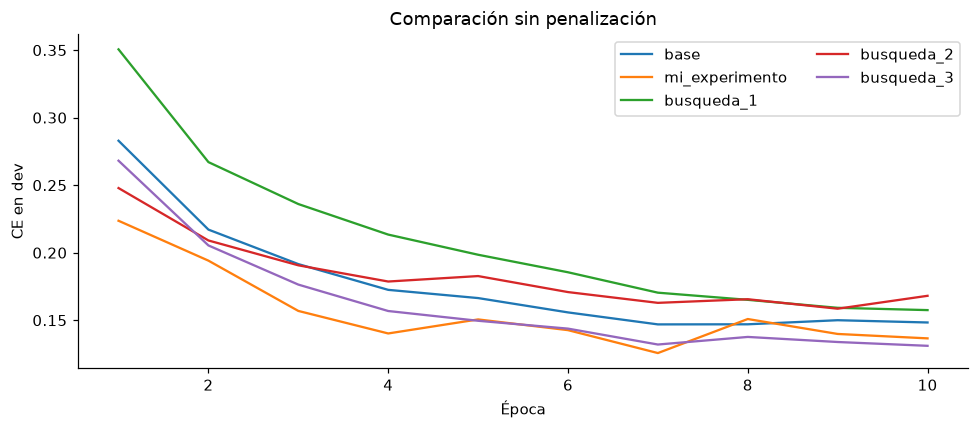

In [28]:
def tabla_resultados(resultados):
    filas=[]
    for nombre,r in resultados.items():
        cfg=r["cfg"]
        filas.append({"modelo":nombre,"CE_train":r["train"]["CE"],"CE_dev":r["dev"]["CE"],
            "acc_train":r["train"]["accuracy"],"acc_dev":r["dev"]["accuracy"],
            "brecha":r["train"]["accuracy"]-r["dev"]["accuracy"],"epoca_elegida":r["mejor_epoca"],
            "actualizaciones":cfg.epocas*int(np.ceil(m_train/cfg.t)),
            "segundos":r["history"].segundos.iloc[-1],
            "parametros_entrenables":sum(int(np.prod(v.shape)) for v in r["modelo"].trainable_variables)})
    return pd.DataFrame(filas).sort_values(["CE_dev","modelo"]).reset_index(drop=True)

tabla=tabla_resultados(resultados)
display(tabla.round(4))
nombre_elegido=tabla.iloc[0]["modelo"]
elegido=resultados[nombre_elegido]
print("Seleccionado con dev:",nombre_elegido)
print("Configuración:",asdict(elegido["cfg"]))
if len(resultados)>1:
    fig,ax=plt.subplots(figsize=(9,4))
    for nombre,r in resultados.items():
        ax.plot(r["history"].epoca,r["history"].CE_dev,label=nombre)
    ax.set(xlabel="Época",ylabel="CE en dev",title="Comparación sin penalización")
    ax.legend(ncol=2);plt.tight_layout();plt.show()

**RESPUESTA DEL ESTUDIANTE 6.** ¿Cuál elegiste y con qué evidencia? ¿Por qué menor CE y mayor exactitud no necesariamente eligen el mismo modelo? Deja escrita tu decisión antes de abrir test.

_Escribe aquí._

## 10. Evaluación final y errores
Cambia `EVALUAR_TEST=True` solo después de completar las comparaciones y justificar tu selección. La celda consulta test para el modelo elegido. Si luego ajustas usando sus errores, ese test ya participa en el desarrollo.

Accuracy es la proporción correcta. Macro-F1 promedia F1 dando el mismo peso a cada clase. La matriz de confusión usa dígitos 0–9. Softmax no asegura que sus probabilidades estén calibradas ni reconoce automáticamente imágenes ajenas al problema.

In [25]:
def probabilidades(modelo,X,t=1024):
    return np.concatenate([tf.nn.softmax(forward_propagation(X[:,i:i+t],modelo),axis=0).numpy()
                           for i in range(0,X.shape[1],t)],axis=1)

EVALUAR_TEST=False
metricas_test=None
if EVALUAR_TEST:
    X_test=preprocess_images(imagenes_test)
    Y_test=one_hot_matrix(y_test,C).numpy()
    A_test=probabilidades(elegido["modelo"],X_test)
    Y_hat_test=A_test.argmax(axis=0)
    metricas_test={**evaluar(elegido["modelo"],X_test,Y_test),
                   "F1_macro":f1_score(y_test,Y_hat_test,average="macro")}
    display(pd.DataFrame([metricas_test],index=[nombre_elegido]))
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay.from_predictions(y_test,Y_hat_test,labels=np.arange(C),
        display_labels=np.arange(C),cmap="Blues",colorbar=False,ax=ax)
    ax.set(xlabel="Clase predicha",ylabel="Clase real",title="Test · modelo elegido")
    plt.tight_layout();plt.show()
    errores=np.flatnonzero(Y_hat_test!=y_test)[:6]
    if len(errores):
        fig,axes=plt.subplots(1,len(errores),figsize=(2.1*len(errores),2.6),squeeze=False)
        for ax,i in zip(axes.flat,errores):
            ax.imshow(imagenes_test[i],cmap="gray")
            ax.set_title(f"Real {y_test[i]} / Pred {Y_hat_test[i]}\np={A_test[:,i].max():.2f}",fontsize=9)
            ax.axis("off")
        plt.tight_layout();plt.show()
else:
    print("Test reservado: termina los experimentos y justifica tu elección con dev.")

Test reservado: termina los experimentos y justifica tu elección con dev.


### 10.1 Una imagen propia (opcional)
Usa un solo dígito centrado en una imagen cuadrada, con margen. Si es oscuro sobre fondo claro, activa `INVERTIR=True`. La función convierte a escala de grises, ajusta a 28×28 y aplica el mismo escalamiento por 255.

No segmenta ni centra automáticamente una fotografía. Sombras, perspectiva y fondos pueden producir un cambio de distribución. El modelo siempre elegirá uno de diez dígitos, aunque la imagen no sea un dígito.

Esta actividad usa el modelo ya seleccionado; deja `RUTA_IMAGEN=None` si no tienes un archivo.

In [26]:
def cargar_imagen_propia(ruta,invertir=True):
    from PIL import Image,ImageOps
    with Image.open(ruta) as archivo:
        imagen=archivo.convert("L")
    if invertir:
        imagen=ImageOps.invert(imagen)
    imagen=imagen.resize((28,28),Image.Resampling.LANCZOS)
    return np.asarray(imagen)

RUTA_IMAGEN=None
INVERTIR=True
if RUTA_IMAGEN is not None:
    imagen=cargar_imagen_propia(RUTA_IMAGEN,INVERTIR)
    p=probabilidades(elegido["modelo"],preprocess_images(imagen[None,...]))[:,0]
    fig,axes=plt.subplots(1,2,figsize=(8,3))
    axes[0].imshow(imagen,cmap="gray",vmin=0,vmax=255);axes[0].axis("off")
    axes[0].set_title(f"Predicción: {p.argmax()}")
    axes[1].bar(np.arange(C),p);axes[1].set(xlabel="Clase",ylabel="Probabilidad",xticks=np.arange(C),ylim=(0,1))
    plt.tight_layout();plt.show()

## 11. Entrega y cierre
Entrega esta notebook con las seis respuestas, las configuraciones efectivamente ejecutadas, la tabla de dev, al menos dos gráficas interpretadas y la evaluación final. Añade una conclusión de 150–250 palabras: qué mejoró, qué no, limitaciones y qué probarías después.

**Actividad de programación:** en una copia, reconstruye el generador `mini_batches` y el bloque entre `GradientTape` y `apply_gradients`. Usa las comprobaciones incluidas para revisar tu implementación. Explica la función de cada línea; no basta con copiarla.

| Criterio | Peso |
|---|---:|
| Nomenclatura, dimensiones y explicación del entrenamiento | 25% |
| Comparaciones controladas y uso correcto de train/dev/test | 35% |
| Interpretación de resultados y limitaciones | 30% |
| Claridad de la entrega | 10% |

### Conclusión del estudiante
_Escribe aquí._

### Referencias
Conceptos del Course 2 de Andrew Ng / DeepLearning.AI, con implementación educativa en TensorFlow 2.
